# 01 — Khai phá dữ liệu MNIST

Kiểm tra dữ liệu, phân phối nhãn và đặc điểm ảnh trước khi huấn luyện. Phân tích chi tiết chỉ dùng 60.000 ảnh train gốc. Hình và bảng được lưu tại `results/eda/`.

## 1. Import và nạp dữ liệu


In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist

SEED = 42
OUTPUT = ROOT / 'results' / 'eda'
OUTPUT.mkdir(parents=True, exist_ok=True)
X_all, y_all, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=10000, stratify=y_all, random_state=SEED)
del X_all, y_all

## 2. Kiểm tra dữ liệu

In [8]:
overview = pd.DataFrame([
    {'split': name, 'X_shape': str(X.shape), 'y_shape': str(y.shape),
     'X_dtype': str(X.dtype), 'y_dtype': str(y.dtype),
     'pixel_min': X.min(), 'pixel_max': X.max(), 'nonfinite': (~np.isfinite(X)).sum()}
    for name, X, y in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]
])
display(overview)
print('Nhãn train:', np.unique(y_train))
print('Nhãn validation :', np.unique(y_val))
print('Nhãn test :', np.unique(y_test))
overview.to_csv(OUTPUT / 'data_overview.csv', index=False)

,split,X_shape,y_shape,X_dtype,y_dtype,pixel_min,pixel_max,nonfinite
0,Train,"(50000, 784)","(50000,)",float32,uint8,0.0,1.0,0
1,Validation,"(10000, 784)","(10000,)",float32,uint8,0.0,1.0,0
2,Test,"(10000, 784)","(10000,)",float32,uint8,0.0,1.0,0


Nhãn train: [0 1 2 3 4 5 6 7 8 9]
Nhãn validation : [0 1 2 3 4 5 6 7 8 9]
Nhãn test : [0 1 2 3 4 5 6 7 8 9]


## 3. Phân bố lớp



TRAIN — 50,000 ảnh


,digit,count,percentage
0,0,4936,9.87
1,1,5618,11.24
2,2,4965,9.93
3,3,5109,10.22
4,4,4868,9.74
5,5,4518,9.04
6,6,4932,9.86
7,7,5221,10.44
8,8,4876,9.75
9,9,4957,9.91


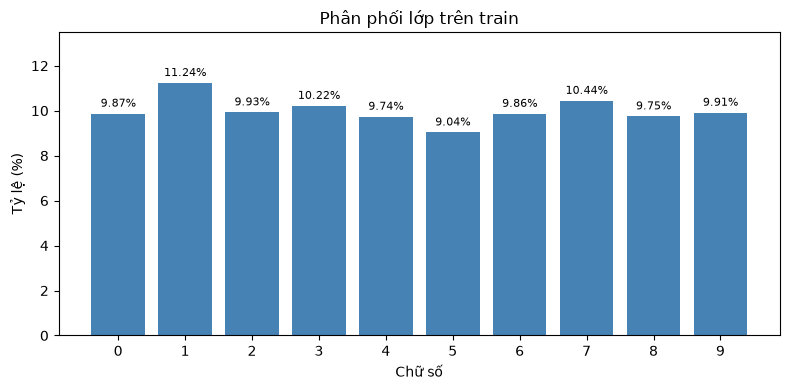

Lớp ít nhất: [5] — 4,518 ảnh/lớp (9.04%).
Lớp nhiều nhất: [1] — 5,618 ảnh/lớp (11.24%).

VAL — 10,000 ảnh


,digit,count,percentage
0,0,987,9.87
1,1,1124,11.24
2,2,993,9.93
3,3,1022,10.22
4,4,974,9.74
5,5,903,9.03
6,6,986,9.86
7,7,1044,10.44
8,8,975,9.75
9,9,992,9.92


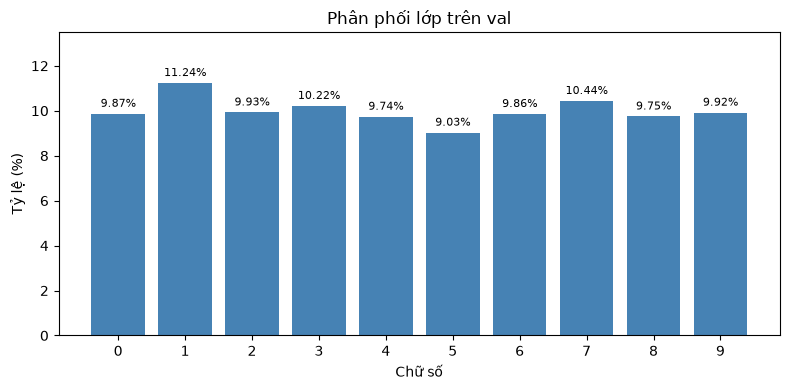

Lớp ít nhất: [5] — 903 ảnh/lớp (9.03%).
Lớp nhiều nhất: [1] — 1,124 ảnh/lớp (11.24%).

TEST — 10,000 ảnh


,digit,count,percentage
0,0,980,9.80
1,1,1135,11.35
2,2,1032,10.32
3,3,1010,10.10
4,4,982,9.82
5,5,892,8.92
6,6,958,9.58
7,7,1028,10.28
8,8,974,9.74
9,9,1009,10.09


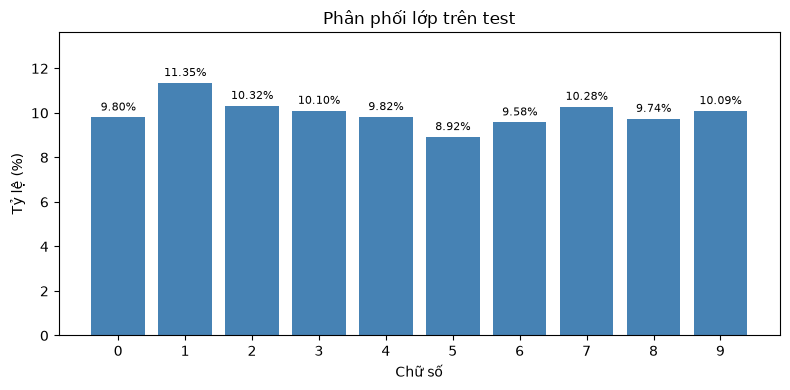

Lớp ít nhất: [5] — 892 ảnh/lớp (8.92%).
Lớp nhiều nhất: [1] — 1,135 ảnh/lớp (11.35%).


In [9]:
for name, y in [('train', y_train), ('val', y_val), ('test', y_test)]:
    counts = np.bincount(y, minlength=10)
    percentages = counts / len(y) * 100
    class_table = pd.DataFrame({
        'digit': np.arange(10), 'count': counts, 'percentage': percentages
    })
    print(f'\n{name.upper()} — {len(y):,} ảnh')
    display(class_table.round(2))
    class_table.to_csv(OUTPUT / f'class_distribution_{name}.csv', index=False)

    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(np.arange(10), percentages, color='steelblue')
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=8)
    ax.set(
        xticks=np.arange(10), xlabel='Chữ số', ylabel='Tỷ lệ (%)',
        title=f'Phân phối lớp trên {name}',
        ylim=(0, percentages.max() * 1.2)
    )
    fig.tight_layout()
    fig.savefig(OUTPUT / f'class_distribution_{name}.png', dpi=300)
    plt.show()
    plt.close(fig)

    least = class_table.loc[class_table['count'] == counts.min(), 'digit'].tolist()
    most = class_table.loc[class_table['count'] == counts.max(), 'digit'].tolist()
    print(f'Lớp ít nhất: {least} — {counts.min():,} ảnh/lớp ({percentages.min():.2f}%).')
    print(f'Lớp nhiều nhất: {most} — {counts.max():,} ảnh/lớp ({percentages.max():.2f}%).')

## 4. Cường độ pixel

Tỷ lệ pixel bằng 0: 80.86%
Tỷ lệ pixel bằng 1: 0.66%
Số vị trí pixel luôn bằng 0 trên toàn bộ train: 72/784


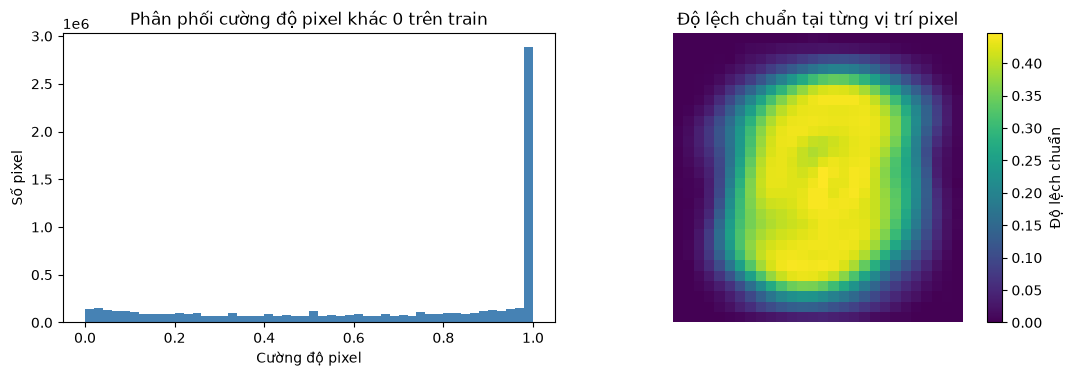

In [10]:
pixels = X_train.reshape(-1, 784)
pixel_std = pixels.std(axis=0)
always_zero = np.all(pixels == 0, axis=0)

print(f'Tỷ lệ pixel bằng 0: {np.mean(pixels == 0) * 100:.2f}%')
print(f'Tỷ lệ pixel bằng 1: {np.mean(pixels == 1) * 100:.2f}%')
print(f'Số vị trí pixel luôn bằng 0 trên toàn bộ train: {always_zero.sum()}/784')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(pixels[pixels > 0], bins=50, range=(0, 1), color='steelblue')
axes[0].set(
    xlabel='Cường độ pixel', ylabel='Số pixel',
    title='Phân phối cường độ pixel khác 0 trên train'
)

im = axes[1].imshow(pixel_std.reshape(28, 28), cmap='viridis')
axes[1].set_title('Độ lệch chuẩn tại từng vị trí pixel')
axes[1].axis('off')
fig.colorbar(im, ax=axes[1], label='Độ lệch chuẩn')

fig.tight_layout()
fig.savefig(OUTPUT / 'pixel_intensity_std.png', dpi=300)
plt.show()
plt.close(fig)

## 5. Ảnh trung bình và lượng mực

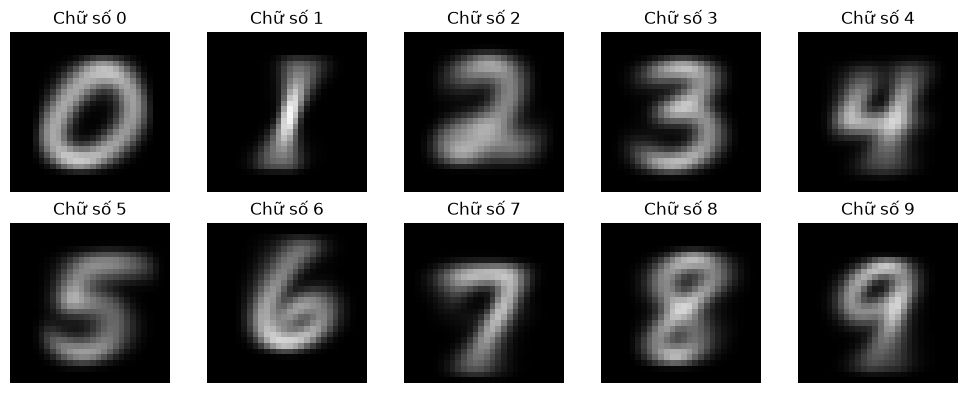

,digit,mean_ink
0,0,135.850006
1,1,59.480000
2,2,116.959999
3,3,111.010002
4,4,95.330002
5,5,100.959999
6,6,107.919998
7,7,89.910004
8,8,117.800003
9,9,96.320000


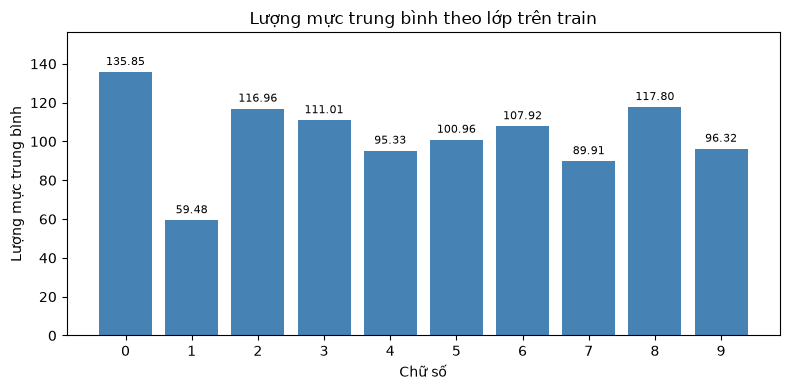

In [11]:
pixels = X_train.reshape(-1, 784)
mean_images = np.array([pixels[y_train == digit].mean(axis=0) for digit in range(10)])
mean_ink = mean_images.sum(axis=1)

# Ảnh trung bình của từng chữ số
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    ax.imshow(mean_images[digit].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Chữ số {digit}')
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT / 'class_mean_images.png', dpi=300)
plt.show()
plt.close(fig)

# Bảng và biểu đồ lượng mực trung bình
ink_table = pd.DataFrame({'digit': np.arange(10), 'mean_ink': mean_ink})
display(ink_table.round(2))
ink_table.to_csv(OUTPUT / 'class_mean_ink.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(np.arange(10), mean_ink, color='steelblue')
ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=8)
ax.set(
    xticks=np.arange(10), xlabel='Chữ số', ylabel='Lượng mực trung bình',
    title='Lượng mực trung bình theo lớp trên train',
    ylim=(0, mean_ink.max() * 1.15)
)
fig.tight_layout()
fig.savefig(OUTPUT / 'class_mean_ink.png', dpi=300)
plt.show()
plt.close(fig)


## 5. Khoảng cách Euclid giữa các lớp

,0,1,2,3,4,5,6,7,8,9
0,0.00,7.56,5.63,5.57,6.23,4.52,5.69,6.36,5.60,6.16
1,7.56,0.00,5.09,5.14,5.68,4.84,5.69,5.38,4.77,5.32
2,5.63,5.09,0.00,4.41,4.74,4.53,3.94,5.38,3.86,4.93
3,5.57,5.14,4.41,0.00,5.26,3.11,5.37,5.23,3.64,4.78
4,6.23,5.68,4.74,5.26,0.00,4.13,4.29,4.04,4.34,2.48
5,4.52,4.84,4.53,3.11,4.13,0.00,4.37,4.49,3.11,3.77
6,5.69,5.69,3.94,5.37,4.29,4.37,0.00,5.69,4.68,4.72
7,6.36,5.38,5.38,5.23,4.04,4.49,5.69,0.00,4.80,2.99
8,5.60,4.77,3.86,3.64,4.34,3.11,4.68,4.80,0.00,3.82
9,6.16,5.32,4.93,4.78,2.48,3.77,4.72,2.99,3.82,0.00


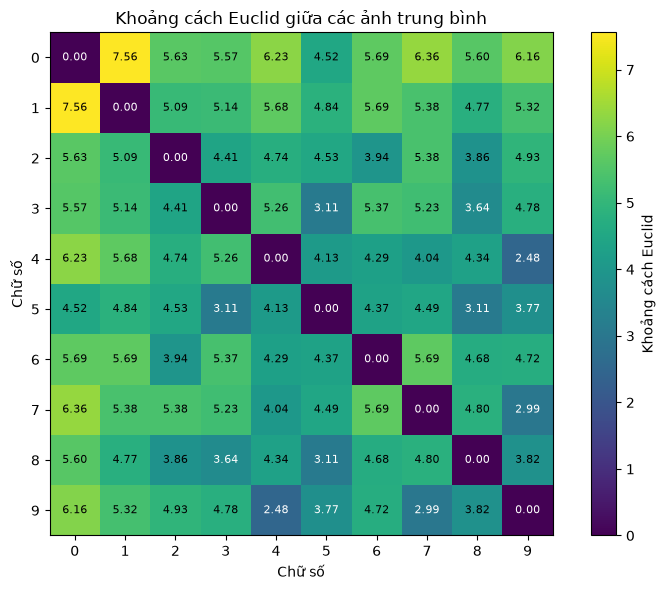

3 cặp có ảnh trung bình gần nhau nhất:


,digit_1,digit_2,distance
34,4,9,2.483
43,7,9,2.988
25,3,5,3.108


In [12]:
distances = np.linalg.norm(mean_images[:, None, :] - mean_images[None, :, :], axis=2)
distance_table = pd.DataFrame(distances, index=range(10), columns=range(10))
display(distance_table.round(2))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(distances, cmap='viridis')
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{distances[i, j]:.2f}', ha='center', va='center',
                fontsize=8, color='white' if distances[i, j] < distances.max() / 2 else 'black')
ax.set(
    xticks=np.arange(10), yticks=np.arange(10),
    xlabel='Chữ số', ylabel='Chữ số',
    title='Khoảng cách Euclid giữa các ảnh trung bình'
)
fig.colorbar(im, ax=ax, label='Khoảng cách Euclid')
fig.tight_layout()
fig.savefig(OUTPUT / 'class_mean_distances.png', dpi=300)
plt.show()
plt.close(fig)

i, j = np.triu_indices(10, k=1)
nearest_pairs = pd.DataFrame({
    'digit_1': i, 'digit_2': j, 'distance': distances[i, j]
}).sort_values('distance').head(3)

print('3 cặp có ảnh trung bình gần nhau nhất:')
display(nearest_pairs.round(3))
nearest_pairs.to_csv(OUTPUT / 'nearest_class_pairs.csv', index=False)


## 6. Kết luận

- Dùng chung đầu vào 784 đặc trưng, pixel chia 255 và nhãn nguyên cho các mô hình.
- Đánh giá bằng accuracy cùng các độ đo macro và confusion matrix.
- Chia 50.000 train / 10.000 validation bằng `test_size=10000, stratify=y, random_state=42`; giữ 10.000 test cho đánh giá cuối.
- Các hình EDA chỉ định hướng phân tích; kết luận về mô hình dựa trên thí nghiệm phân lớp.

Hình PNG 300 dpi và bảng CSV nằm trong `results/eda/`; chạy lại ghi đè file cùng tên.
